In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from scipy.stats import pearsonr, spearmanr

In [87]:
results_path = Path("../results")

participant_ids = [
    "CDT_P001",
    "CDT_P002",
    "CDT_P003",
    "CDT_P004",
    "CDT_P005"
]

matrices = {}

for pid in participant_ids:

    matrix_file = results_path / pid / f"{pid}_matrix.csv"

    mat = pd.read_csv(
        matrix_file,
        header=None
    ).values.astype(float)

    matrices[pid] = mat

    print(
        pid,
        mat.shape,
        "NaNs:",
        np.isnan(mat).sum()
    )

CDT_P001 (27, 27) NaNs: 2
CDT_P002 (27, 27) NaNs: 23
CDT_P003 (27, 27) NaNs: 40
CDT_P004 (27, 27) NaNs: 60
CDT_P005 (27, 27) NaNs: 34


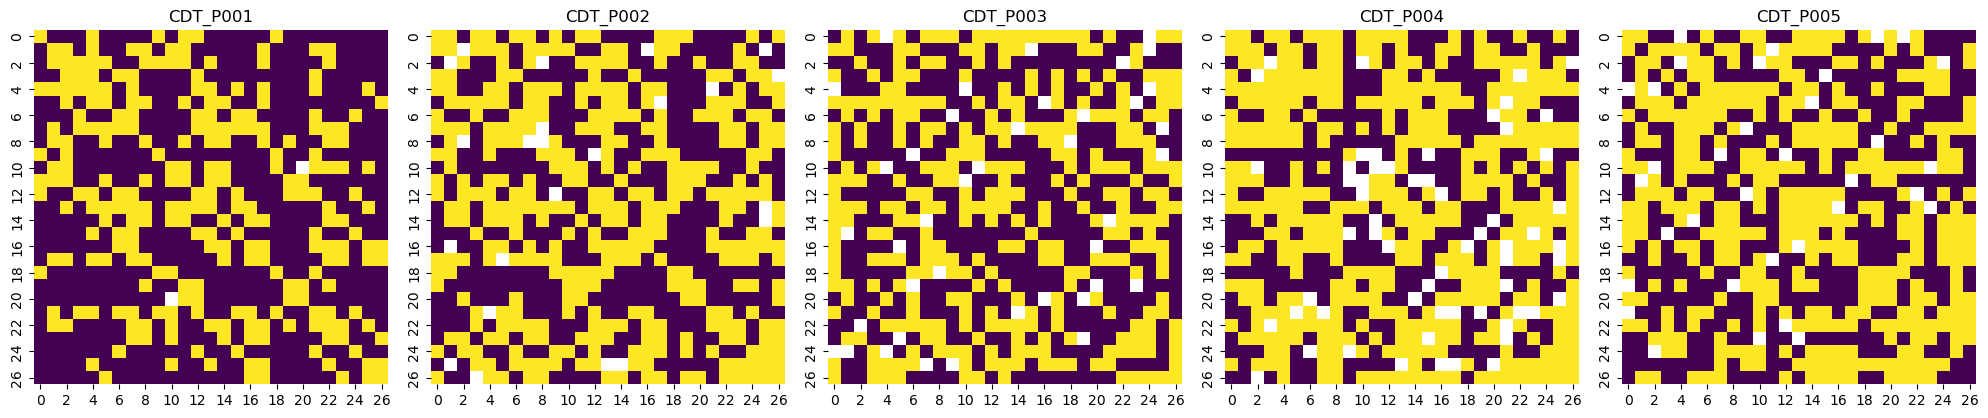

In [88]:
fig, axes = plt.subplots(1,5, figsize=(20,4))

for ax, pid in zip(axes, participant_ids):

    sns.heatmap(
        matrices[pid],
        ax=ax,
        cmap="viridis",
        square=True,
        cbar=False
    )

    ax.set_title(pid)

plt.tight_layout()
plt.show()

In [90]:
agreement = []

for i in range(len(participant_ids)):
    for j in range(i+1, len(participant_ids)):

        p1 = matrices[participant_ids[i]]
        p2 = matrices[participant_ids[j]]

        idx = np.triu_indices(27)

        v1 = p1[idx]
        v2 = p2[idx]

        mask = (
            ~np.isnan(v1)
            &
            ~np.isnan(v2)
        )

        r,_ = pearsonr(
            v1[mask],
            v2[mask]
        )

        agreement.append(r)

        print(
            participant_ids[i],
            participant_ids[j],
            round(r,3)
        )

print()
print("Mean agreement =", round(np.mean(agreement),3))

CDT_P001 CDT_P002 0.385
CDT_P001 CDT_P003 0.257
CDT_P001 CDT_P004 0.313
CDT_P001 CDT_P005 0.242
CDT_P002 CDT_P003 0.246
CDT_P002 CDT_P004 0.352
CDT_P002 CDT_P005 0.231
CDT_P003 CDT_P004 0.267
CDT_P003 CDT_P005 0.138
CDT_P004 CDT_P005 0.213

Mean agreement = 0.264


In [91]:
group_matrix = np.nanmean(
    np.stack(list(matrices.values())),
    axis=0
)

print(
    "Remaining NaNs:",
    np.isnan(group_matrix).sum()
)

Remaining NaNs: 0


In [92]:
rows, cols = np.where(
    np.isnan(group_matrix)
)

for r,c in zip(rows,cols):
    print(r,c)

In [93]:
group_mean = np.nanmean(group_matrix)

group_matrix = np.nan_to_num(
    group_matrix,
    nan=group_mean
)

print(
    np.isnan(group_matrix).sum()
)

0


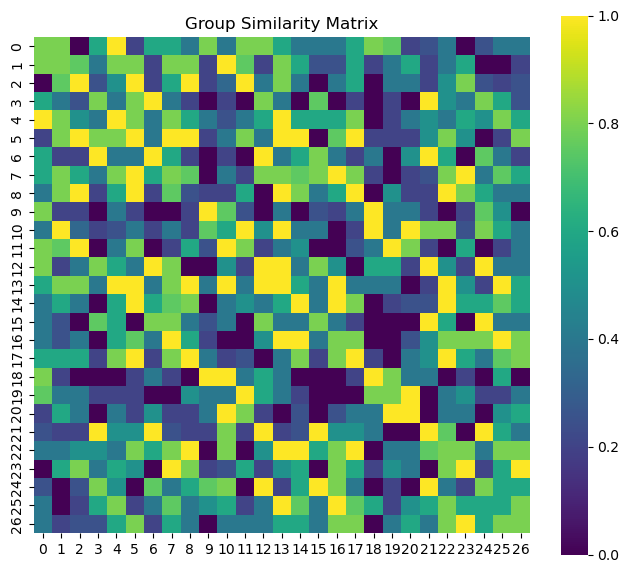

In [94]:
plt.figure(figsize=(8,7))

sns.heatmap(
    group_matrix,
    cmap="viridis",
    square=True
)

plt.title(
    "Group Similarity Matrix"
)

plt.show()

In [95]:
stim_info = []

for tone in [2,3,4]:
    for ifi in [50,100,150]:
        for am in [0.3,0.6,0.9]:

            stim_info.append(
                [tone,ifi,am]
            )

stim_df = pd.DataFrame(
    stim_info,
    columns=[
        "ToneCount",
        "IFI",
        "AM"
    ]
)

stim_df

,ToneCount,IFI,AM
0,2,50,0.3
1,2,50,0.6
2,2,50,0.9
3,2,100,0.3
4,2,100,0.6
5,2,100,0.9
6,2,150,0.3
7,2,150,0.6
8,2,150,0.9
9,3,50,0.3


In [96]:
same_tone = []
diff_tone = []

same_ifi = []
diff_ifi = []

same_am = []
diff_am = []

for i in range(27):

    for j in range(i+1,27):

        sim = group_matrix[i,j]

        if stim_df.iloc[i]["ToneCount"] == stim_df.iloc[j]["ToneCount"]:
            same_tone.append(sim)
        else:
            diff_tone.append(sim)

        if stim_df.iloc[i]["IFI"] == stim_df.iloc[j]["IFI"]:
            same_ifi.append(sim)
        else:
            diff_ifi.append(sim)

        if stim_df.iloc[i]["AM"] == stim_df.iloc[j]["AM"]:
            same_am.append(sim)
        else:
            diff_am.append(sim)

print("TONE COUNT")
print("same =", round(np.mean(same_tone),3))
print("different =", round(np.mean(diff_tone),3))

print()

print("IFI")
print("same =", round(np.mean(same_ifi),3))
print("different =", round(np.mean(diff_ifi),3))

print()

print("AM DEPTH")
print("same =", round(np.mean(same_am),3))
print("different =", round(np.mean(diff_am),3))

TONE COUNT
same = 0.498
different = 0.465

IFI
same = 0.602
different = 0.419

AM DEPTH
same = 0.617
different = 0.412


In [97]:
dissimilarity = 1 - group_matrix

np.fill_diagonal(
    dissimilarity,
    0
)

dissimilarity[:5,:5]

array([[0.  , 0.2 , 1.  , 0.4 , 0.  ],
       [0.2 , 0.  , 0.25, 0.6 , 0.2 ],
       [1.  , 0.25, 0.  , 0.75, 0.5 ],
       [0.4 , 0.6 , 0.75, 0.  , 0.6 ],
       [0.  , 0.2 , 0.5 , 0.6 , 0.  ]])

In [98]:
from sklearn.manifold import MDS

In [99]:
mds_2d = MDS(
    n_components=2,
    dissimilarity='precomputed',
    random_state=42
)

coords_2d = mds_2d.fit_transform(
    dissimilarity
)

print(
    "Stress:",
    mds_2d.stress_
)

Stress: 12.39613340712574


/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


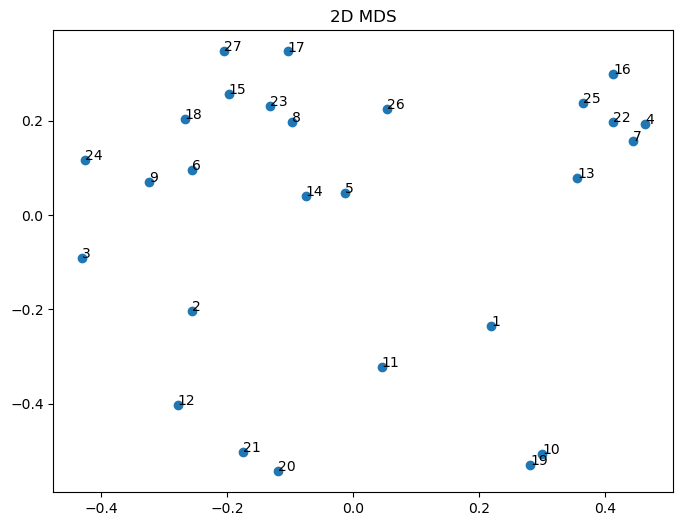

In [100]:
plt.figure(figsize=(8,6))

plt.scatter(
    coords_2d[:,0],
    coords_2d[:,1]
)

for i in range(27):

    plt.text(
        coords_2d[i,0],
        coords_2d[i,1],
        str(i+1)
    )

plt.title("2D MDS")
plt.show()

In [101]:
mds_df = stim_df.copy()

mds_df["x"] = coords_2d[:,0]
mds_df["y"] = coords_2d[:,1]

mds_df.head()

,ToneCount,IFI,AM,x,y
0,2,50,0.3,0.219356,-0.234627
1,2,50,0.6,-0.255201,-0.204087
2,2,50,0.9,-0.430854,-0.090756
3,2,100,0.3,0.463470,0.193254
4,2,100,0.6,-0.012894,0.046447


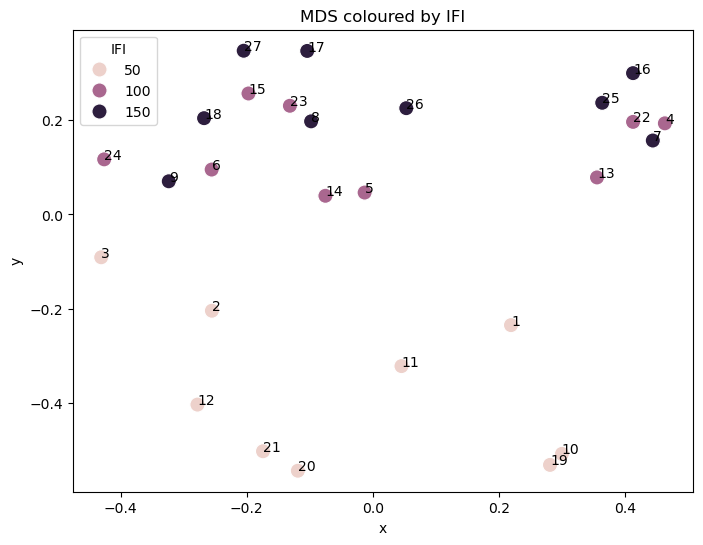

In [102]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=mds_df,
    x="x",
    y="y",
    hue="IFI",
    s=120
)

for i,row in mds_df.iterrows():

    plt.text(
        row["x"],
        row["y"],
        str(i+1)
    )

plt.title("MDS coloured by IFI")
plt.show()

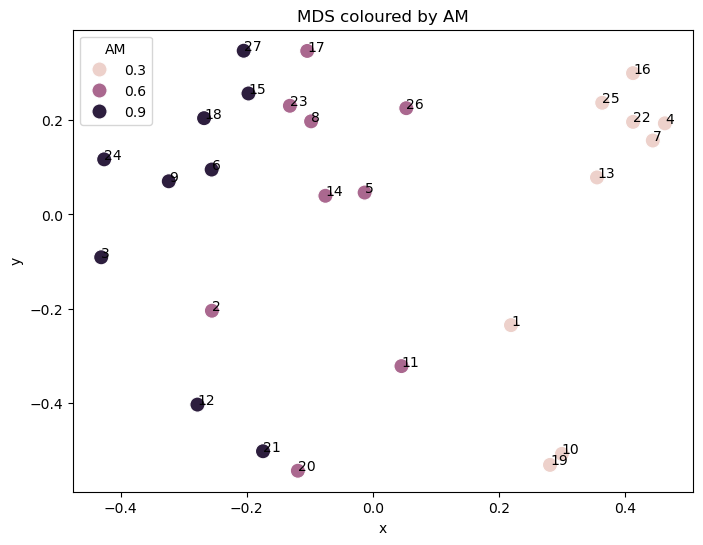

In [103]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=mds_df,
    x="x",
    y="y",
    hue="AM",
    s=120
)

for i,row in mds_df.iterrows():

    plt.text(
        row["x"],
        row["y"],
        str(i+1)
    )

plt.title("MDS coloured by AM")
plt.show()

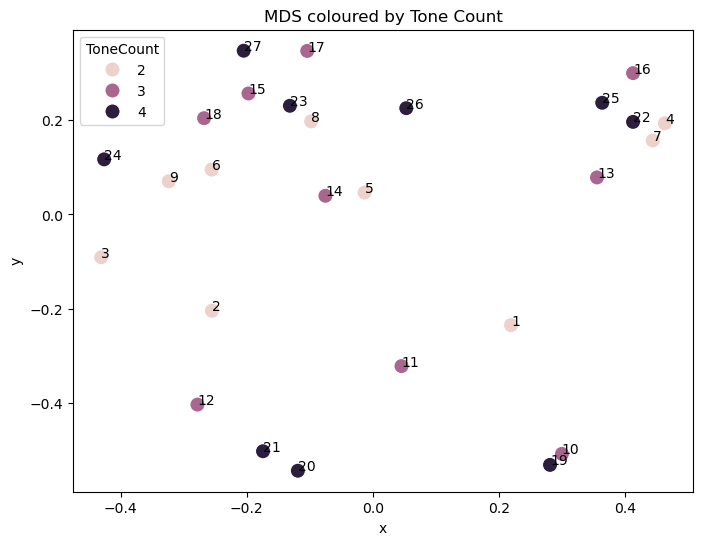

In [104]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=mds_df,
    x="x",
    y="y",
    hue="ToneCount",
    s=120
)

for i,row in mds_df.iterrows():

    plt.text(
        row["x"],
        row["y"],
        str(i+1)
    )

plt.title("MDS coloured by Tone Count")
plt.show()

In [105]:
from scipy.stats import spearmanr

for dim in ["x","y"]:

    print("\n", dim)

    for feature in [
        "ToneCount",
        "IFI",
        "AM"
    ]:

        r,p = spearmanr(
            mds_df[dim],
            mds_df[feature]
        )

        print(
            feature,
            round(r,3),
            round(p,4)
        )


 x
ToneCount 0.058 0.7729
IFI 0.134 0.5054
AM -0.926 0.0

 y
ToneCount 0.116 0.5629
IFI 0.839 0.0
AM 0.035 0.8626


In [106]:
from sklearn.manifold import MDS

for k in [1,2,3,4]:

    mds = MDS(
        n_components=k,
        dissimilarity='precomputed',
        random_state=42
    )

    mds.fit(dissimilarity)

    print(
        k,
        mds.stress_
    )

1 27.561059670781894
2 12.39613340712574
3 11.127088636791617
4 10.890787579973878


/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/p

In [107]:
n = 27

tone_model = np.zeros((n,n))
ifi_model = np.zeros((n,n))
am_model = np.zeros((n,n))

for i in range(n):
    for j in range(n):

        tone_i = stim_df.iloc[i]["ToneCount"]
        tone_j = stim_df.iloc[j]["ToneCount"]

        ifi_i = stim_df.iloc[i]["IFI"]
        ifi_j = stim_df.iloc[j]["IFI"]

        am_i = stim_df.iloc[i]["AM"]
        am_j = stim_df.iloc[j]["AM"]

        # Tone count model
        tone_model[i,j] = abs(tone_i - tone_j)

        # IFI model
        ifi_model[i,j] = abs(ifi_i - ifi_j)

        # AM model
        am_model[i,j] = abs(am_i - am_j)

In [108]:
tone_model = tone_model / np.max(tone_model)
ifi_model = ifi_model / np.max(ifi_model)
am_model = am_model / np.max(am_model)

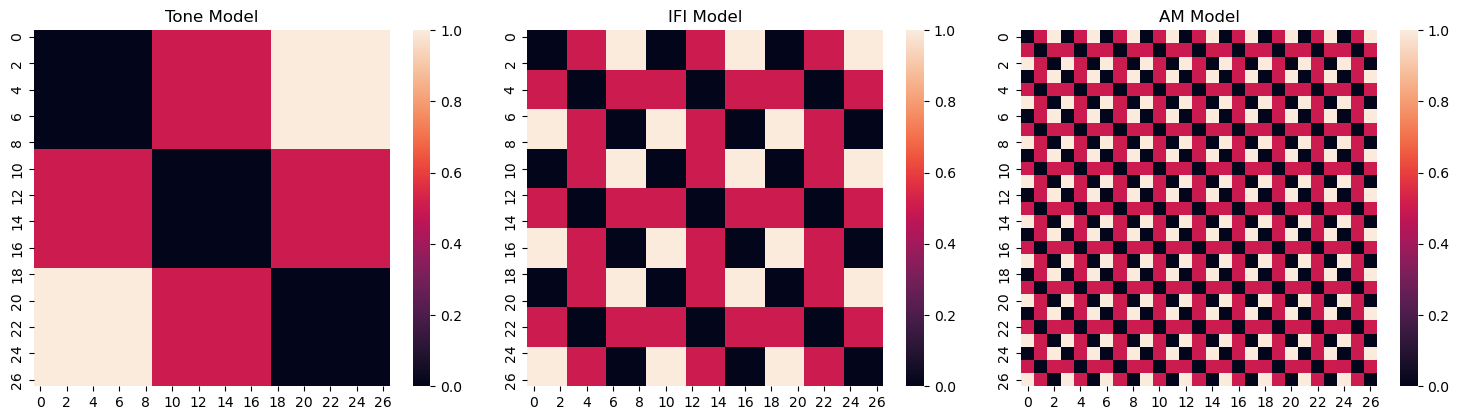

In [109]:
fig,ax = plt.subplots(1,3,figsize=(15,4))

sns.heatmap(tone_model, ax=ax[0], square=True)
ax[0].set_title("Tone Model")

sns.heatmap(ifi_model, ax=ax[1], square=True)
ax[1].set_title("IFI Model")

sns.heatmap(am_model, ax=ax[2], square=True)
ax[2].set_title("AM Model")

plt.tight_layout()
plt.show()

In [110]:
from scipy.stats import spearmanr

idx = np.triu_indices(27, k=1)

perceptual = dissimilarity[idx]

models = {
    "Tone Count": tone_model[idx],
    "IFI": ifi_model[idx],
    "AM Depth": am_model[idx]
}

for name, model in models.items():

    r,p = spearmanr(
        perceptual,
        model
    )

    print(
        f"{name}: r={r:.3f}, p={p:.6f}"
    )

Tone Count: r=0.105, p=0.049598
IFI: r=0.354, p=0.000000
AM Depth: r=0.368, p=0.000000


In [111]:
from sklearn.linear_model import LinearRegression
import pandas as pd

In [113]:
rows = []

for i in range(27):
    for j in range(i+1,27):

        rows.append({

            "Perceptual":
                dissimilarity[i,j],

            "Tone":
                tone_model[i,j],

            "IFI":
                ifi_model[i,j],

            "AM":
                am_model[i,j]
        })

rsa_df = pd.DataFrame(rows)

rsa_df.head()

,Perceptual,Tone,IFI,AM
0,0.2,0.0,0.0,0.5
1,1.0,0.0,0.0,1.0
2,0.4,0.0,0.5,0.0
3,0.0,0.0,0.5,0.5
4,0.8,0.0,0.5,1.0


In [114]:
X = rsa_df[["Tone","IFI","AM"]]

y = rsa_df["Perceptual"]

model = LinearRegression()

model.fit(X,y)

print("R² =", model.score(X,y))

for name,coef in zip(
    ["Tone","IFI","AM"],
    model.coef_
):
    print(name, coef)

R² = 0.36413872768400657
Tone 0.13613445378151243
IFI 0.34202670967376747
AM 0.39876071640777555


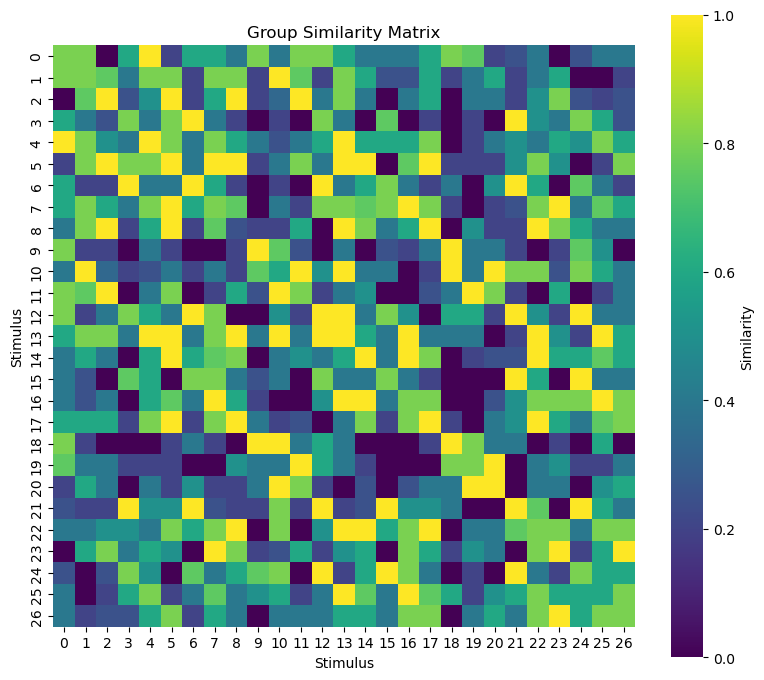

<Figure size 640x480 with 0 Axes>

In [115]:
plt.figure(figsize=(8,7))

sns.heatmap(
    group_matrix,
    cmap="viridis",
    square=True,
    cbar_kws={"label":"Similarity"}
)

plt.xlabel("Stimulus")
plt.ylabel("Stimulus")
plt.title("Group Similarity Matrix")

plt.tight_layout()
plt.show()
plt.savefig("Fig1_GroupSimilarityMatrix.png", dpi=300, bbox_inches='tight')

In [116]:
agreement_matrix = np.full((5,5), np.nan)

for i in range(len(participant_ids)):
    for j in range(i+1,len(participant_ids)):

        p1 = matrices[participant_ids[i]]
        p2 = matrices[participant_ids[j]]

        idx = np.triu_indices(27)

        v1 = p1[idx]
        v2 = p2[idx]

        mask = ~np.isnan(v1) & ~np.isnan(v2)

        r,_ = pearsonr(v1[mask],v2[mask])

        agreement_matrix[i,j] = r
        agreement_matrix[j,i] = r

np.fill_diagonal(agreement_matrix,1)


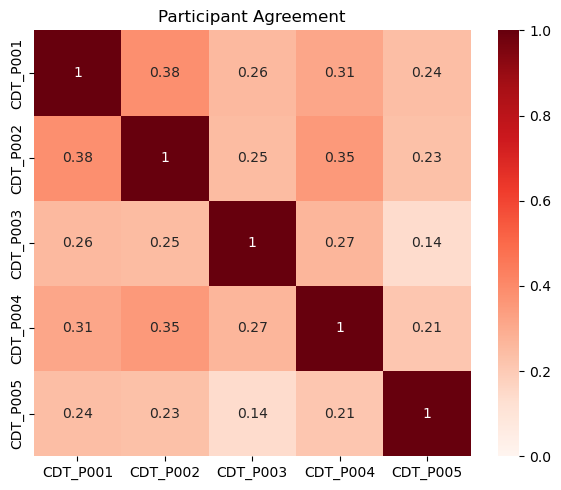

In [117]:
plt.figure(figsize=(6,5))

sns.heatmap(
    agreement_matrix,
    annot=True,
    cmap="Reds",
    vmin=0,
    vmax=1,
    xticklabels=participant_ids,
    yticklabels=participant_ids
)

plt.title("Participant Agreement")
plt.tight_layout()
plt.show()

In [118]:
results = pd.DataFrame({

    "Dimension":[
        "Tone Count",
        "IFI",
        "AM Depth"
    ],

    "Same":[
        np.mean(same_tone),
        np.mean(same_ifi),
        np.mean(same_am)
    ],

    "Different":[
        np.mean(diff_tone),
        np.mean(diff_ifi),
        np.mean(diff_am)
    ]
})

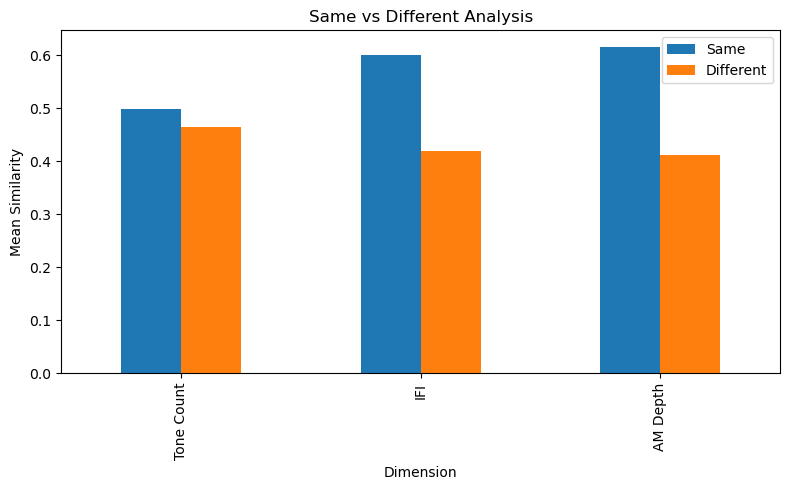

In [119]:
results.set_index("Dimension").plot(
    kind="bar",
    figsize=(8,5)
)

plt.ylabel("Mean Similarity")
plt.title("Same vs Different Analysis")

plt.tight_layout()
plt.show()

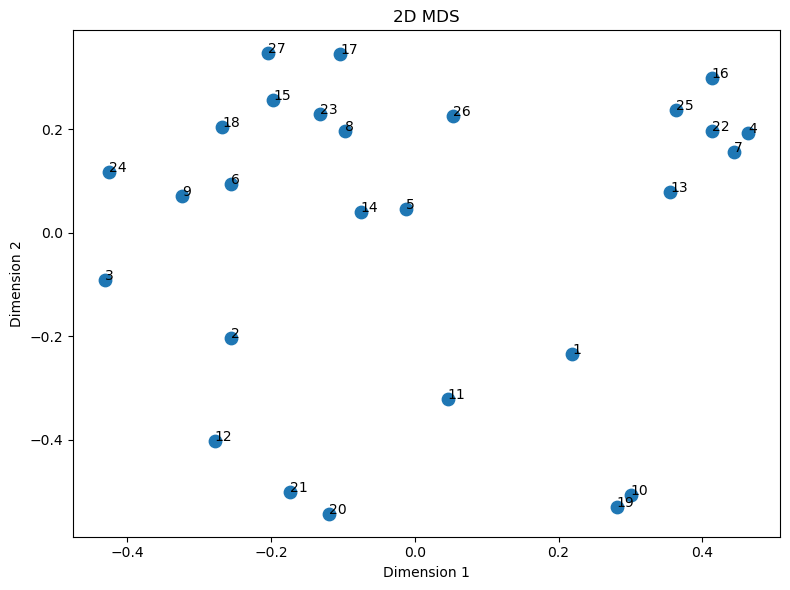

In [120]:
plt.figure(figsize=(8,6))

plt.scatter(
    coords_2d[:,0],
    coords_2d[:,1],
    s=80
)

for i in range(27):
    plt.text(
        coords_2d[i,0],
        coords_2d[i,1],
        str(i+1)
    )

plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.title("2D MDS")

plt.tight_layout()
plt.show()

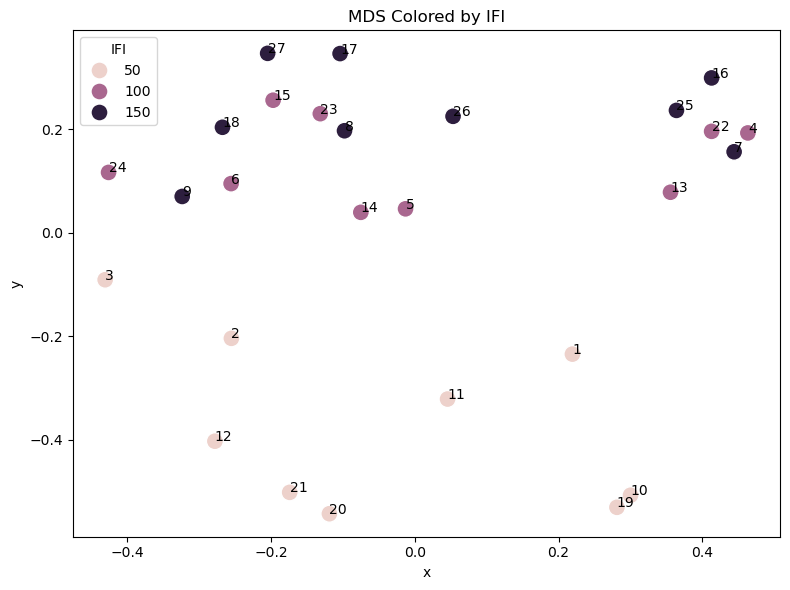

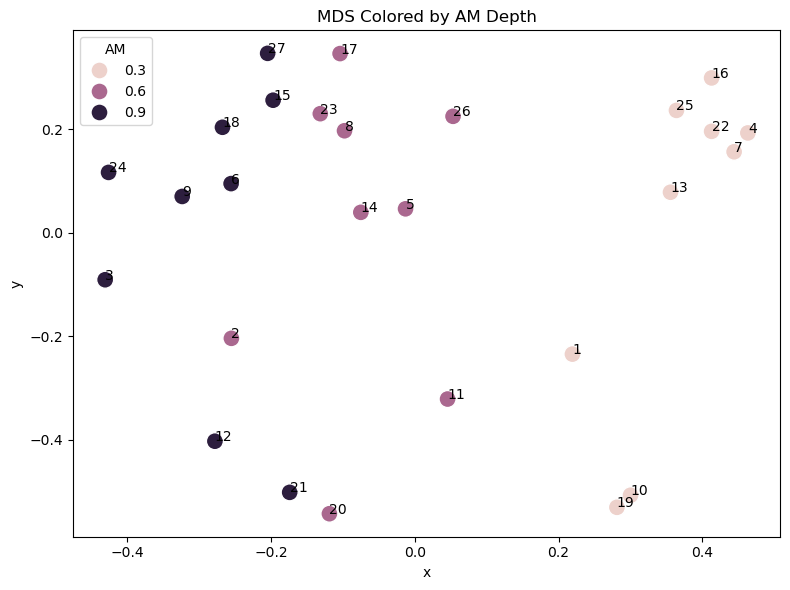

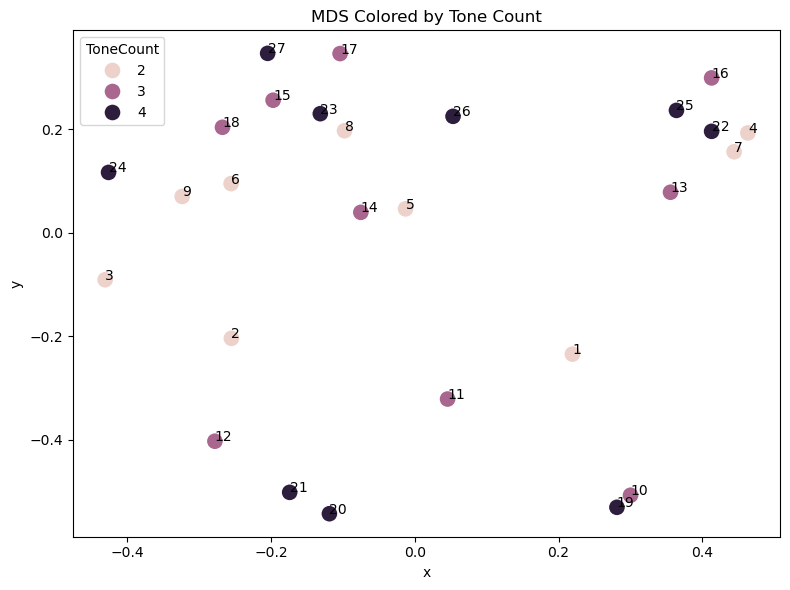

In [121]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=mds_df,
    x="x",
    y="y",
    hue="IFI",
    s=150
)

for i,row in mds_df.iterrows():
    plt.text(row["x"],row["y"],str(i+1))

plt.title("MDS Colored by IFI")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=mds_df,
    x="x",
    y="y",
    hue="AM",
    s=150
)

for i,row in mds_df.iterrows():
    plt.text(row["x"],row["y"],str(i+1))

plt.title("MDS Colored by AM Depth")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=mds_df,
    x="x",
    y="y",
    hue="ToneCount",
    s=150
)

for i,row in mds_df.iterrows():
    plt.text(row["x"],row["y"],str(i+1))

plt.title("MDS Colored by Tone Count")

plt.tight_layout()
plt.show()

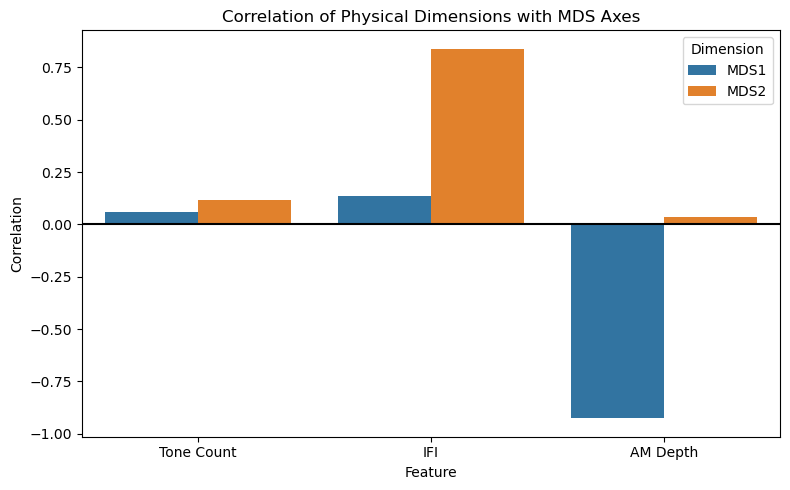

In [122]:
corr_df = pd.DataFrame({

    "Feature":[
        "Tone Count",
        "IFI",
        "AM Depth",
        "Tone Count",
        "IFI",
        "AM Depth"
    ],

    "Correlation":[
        0.058,
        0.134,
        -0.926,
        0.116,
        0.839,
        0.035
    ],

    "Dimension":[
        "MDS1",
        "MDS1",
        "MDS1",
        "MDS2",
        "MDS2",
        "MDS2"
    ]
})
plt.figure(figsize=(8,5))

sns.barplot(
    data=corr_df,
    x="Feature",
    y="Correlation",
    hue="Dimension"
)

plt.axhline(0,color='black')

plt.title("Correlation of Physical Dimensions with MDS Axes")

plt.tight_layout()
plt.show()

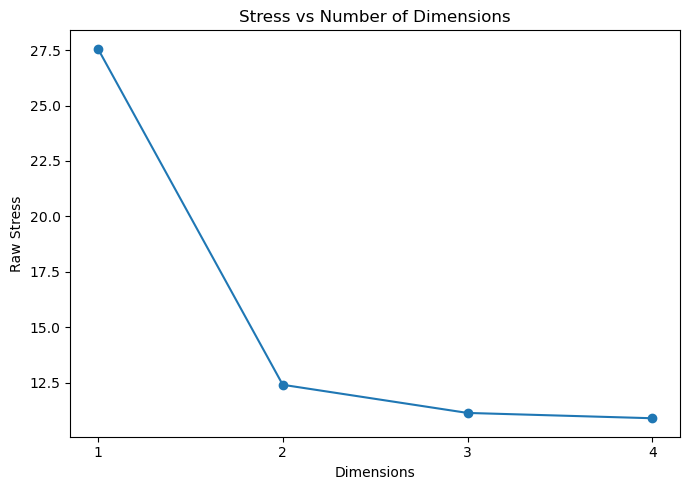

In [123]:
stress_values = [
    27.56,
    12.40,
    11.13,
    10.89
]

dims = [1,2,3,4]
plt.figure(figsize=(7,5))

plt.plot(
    dims,
    stress_values,
    marker="o"
)

plt.xticks(dims)

plt.xlabel("Dimensions")
plt.ylabel("Raw Stress")

plt.title("Stress vs Number of Dimensions")

plt.tight_layout()
plt.show()

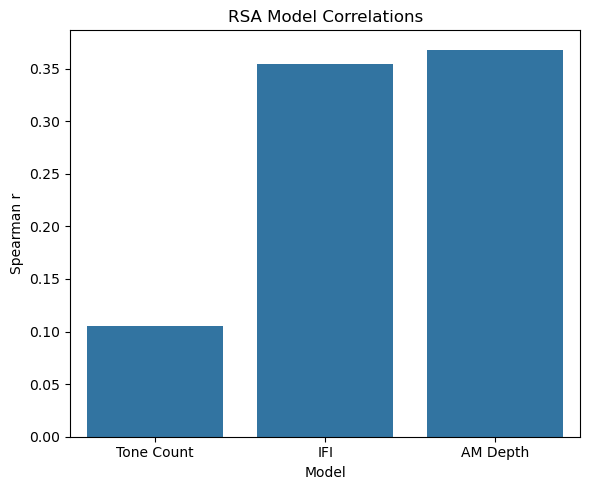

In [124]:
rsa_results = pd.DataFrame({

    "Model":[
        "Tone Count",
        "IFI",
        "AM Depth"
    ],

    "Correlation":[
        0.105,
        0.354,
        0.368
    ]
})
plt.figure(figsize=(6,5))

sns.barplot(
    data=rsa_results,
    x="Model",
    y="Correlation"
)

plt.ylabel("Spearman r")

plt.title("RSA Model Correlations")

plt.tight_layout()
plt.show()

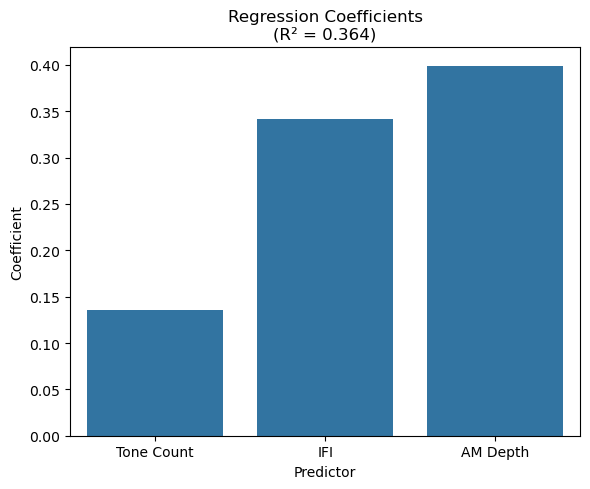

In [125]:
reg_df = pd.DataFrame({

    "Predictor":[
        "Tone Count",
        "IFI",
        "AM Depth"
    ],

    "Coefficient":[
        0.136,
        0.342,
        0.399
    ]
})
plt.figure(figsize=(6,5))

sns.barplot(
    data=reg_df,
    x="Predictor",
    y="Coefficient"
)

plt.title(
    "Regression Coefficients\n(R² = 0.364)"
)

plt.tight_layout()
plt.show()

In [126]:
rows = []

for i in range(27):
    for j in range(i+1,27):

        rows.append({

            "Similarity": group_matrix[i,j],

            "AM_Diff":
                abs(
                    stim_df.iloc[i]["AM"]
                    -
                    stim_df.iloc[j]["AM"]
                ),

            "IFI_Diff":
                abs(
                    stim_df.iloc[i]["IFI"]
                    -
                    stim_df.iloc[j]["IFI"]
                ),

            "Tone_Diff":
                abs(
                    stim_df.iloc[i]["ToneCount"]
                    -
                    stim_df.iloc[j]["ToneCount"]
                )
        })

pair_df = pd.DataFrame(rows)

In [127]:
from sklearn.linear_model import LogisticRegression
import numpy as np

In [128]:
pair_df["Similar"] = (
    pair_df["Similarity"] > 0.5
).astype(int)

In [129]:
X = pair_df[["AM_Diff"]]

y = pair_df["Similar"]

model = LogisticRegression()

model.fit(X,y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [130]:
x_vals = np.linspace(
    pair_df["AM_Diff"].min(),
    pair_df["AM_Diff"].max(),
    200
).reshape(-1,1)

y_pred = model.predict_proba(
    x_vals
)[:,1]

/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


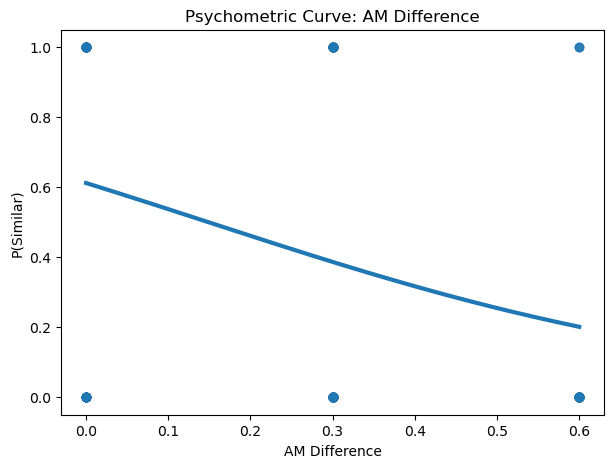

In [131]:
plt.figure(figsize=(7,5))

plt.scatter(
    pair_df["AM_Diff"],
    pair_df["Similar"],
    alpha=0.3
)

plt.plot(
    x_vals,
    y_pred,
    linewidth=3
)

plt.xlabel("AM Difference")
plt.ylabel("P(Similar)")

plt.title(
    "Psychometric Curve: AM Difference"
)

plt.show()

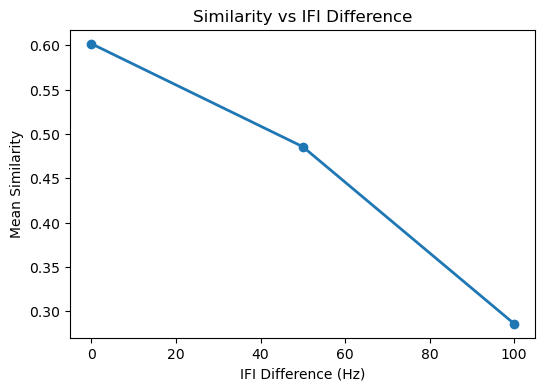

In [132]:
ifi_plot = []

for diff in sorted(pair_df["IFI_Diff"].unique()):

    mean_sim = pair_df[
        pair_df["IFI_Diff"] == diff
    ]["Similarity"].mean()

    ifi_plot.append([diff, mean_sim])

ifi_plot = pd.DataFrame(
    ifi_plot,
    columns=["IFI_Diff","Similarity"]
)

plt.figure(figsize=(6,4))

plt.plot(
    ifi_plot["IFI_Diff"],
    ifi_plot["Similarity"],
    marker='o',
    linewidth=2
)

plt.xlabel("IFI Difference (Hz)")
plt.ylabel("Mean Similarity")

plt.title("Similarity vs IFI Difference")

plt.show()

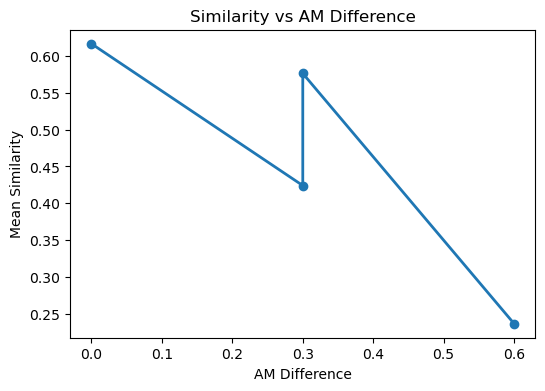

In [133]:
am_plot = []

for diff in sorted(pair_df["AM_Diff"].unique()):

    mean_sim = pair_df[
        pair_df["AM_Diff"] == diff
    ]["Similarity"].mean()

    am_plot.append([diff, mean_sim])

am_plot = pd.DataFrame(
    am_plot,
    columns=["AM_Diff","Similarity"]
)

plt.figure(figsize=(6,4))

plt.plot(
    am_plot["AM_Diff"],
    am_plot["Similarity"],
    marker='o',
    linewidth=2
)

plt.xlabel("AM Difference")
plt.ylabel("Mean Similarity")

plt.title("Similarity vs AM Difference")

plt.show()

In [134]:
pair_df["Different"] = (
    pair_df["Similarity"] < 0.5
).astype(int)
ifi_summary = pair_df.groupby(
    "IFI_Diff"
)["Different"].mean().reset_index()

ifi_summary

,IFI_Diff,Different
0,0.0,0.388889
1,50.0,0.512346
2,100.0,0.765432


/var/folders/z6/xz3cx04d46500b48t3vr_1sr0000gn/T/ipykernel_37272/1775064383.py:5: OptimizeWarning: Covariance of the parameters could not be estimated
  params,_ = curve_fit(


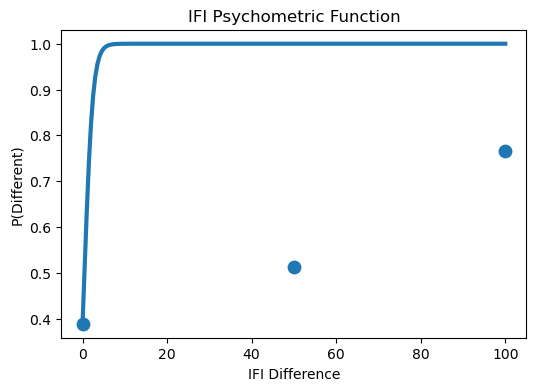

In [135]:
from scipy.optimize import curve_fit
import numpy as np
def sigmoid(x,a,b):
    return 1/(1+np.exp(-(a*x+b)))
params,_ = curve_fit(
    sigmoid,
    ifi_summary["IFI_Diff"],
    ifi_summary["Different"]
)
xfit = np.linspace(0,100,200)

yfit = sigmoid(
    xfit,
    *params
)

plt.figure(figsize=(6,4))

plt.scatter(
    ifi_summary["IFI_Diff"],
    ifi_summary["Different"],
    s=80
)

plt.plot(
    xfit,
    yfit,
    linewidth=3
)

plt.xlabel("IFI Difference")
plt.ylabel("P(Different)")
plt.title("IFI Psychometric Function")

plt.show()

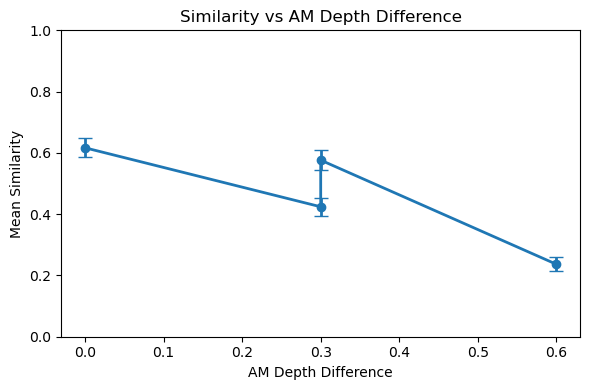

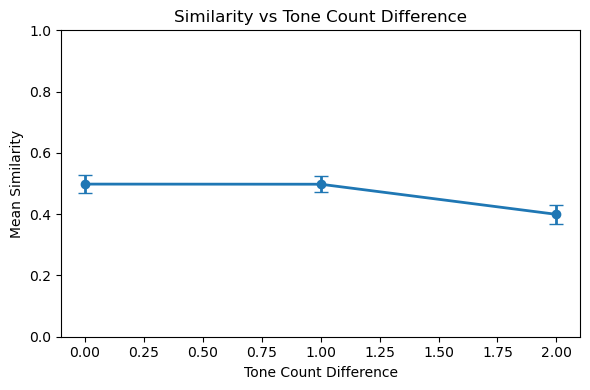

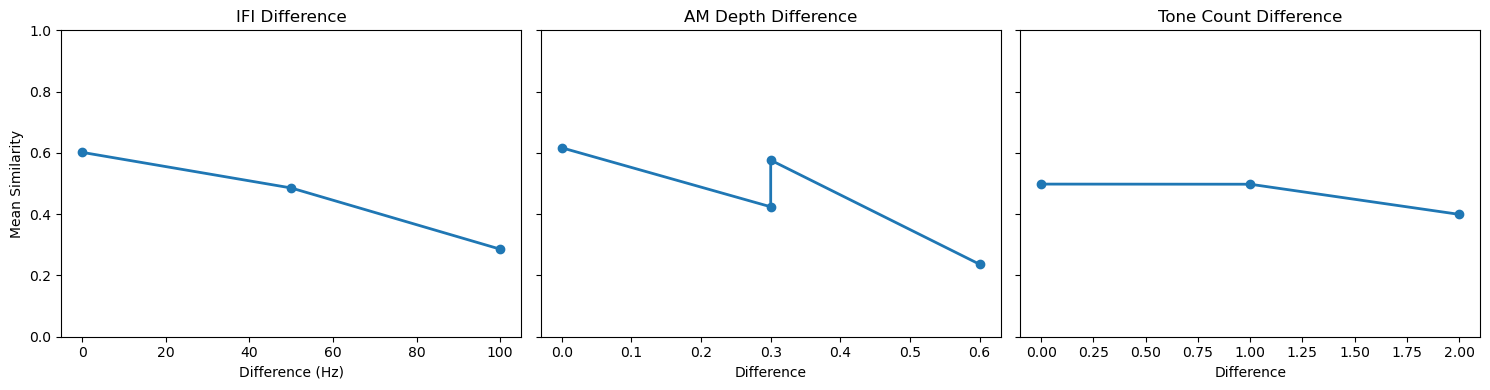

In [136]:
am_plot = []

for diff in sorted(pair_df["AM_Diff"].unique()):

    mean_sim = pair_df[
        pair_df["AM_Diff"] == diff
    ]["Similarity"].mean()

    sem = pair_df[
        pair_df["AM_Diff"] == diff
    ]["Similarity"].sem()

    am_plot.append([
        diff,
        mean_sim,
        sem
    ])

am_plot = pd.DataFrame(
    am_plot,
    columns=[
        "AM_Diff",
        "Similarity",
        "SEM"
    ]
)

am_plot
plt.figure(figsize=(6,4))

plt.errorbar(
    am_plot["AM_Diff"],
    am_plot["Similarity"],
    yerr=am_plot["SEM"],
    marker='o',
    capsize=5,
    linewidth=2
)

plt.xlabel("AM Depth Difference")
plt.ylabel("Mean Similarity")

plt.title(
    "Similarity vs AM Depth Difference"
)

plt.ylim(0,1)

plt.tight_layout()
plt.show()
tone_plot = []

for diff in sorted(pair_df["Tone_Diff"].unique()):

    mean_sim = pair_df[
        pair_df["Tone_Diff"] == diff
    ]["Similarity"].mean()

    sem = pair_df[
        pair_df["Tone_Diff"] == diff
    ]["Similarity"].sem()

    tone_plot.append([
        diff,
        mean_sim,
        sem
    ])

tone_plot = pd.DataFrame(
    tone_plot,
    columns=[
        "Tone_Diff",
        "Similarity",
        "SEM"
    ]
)

tone_plot
plt.figure(figsize=(6,4))

plt.errorbar(
    tone_plot["Tone_Diff"],
    tone_plot["Similarity"],
    yerr=tone_plot["SEM"],
    marker='o',
    capsize=5,
    linewidth=2
)

plt.xlabel("Tone Count Difference")
plt.ylabel("Mean Similarity")

plt.title(
    "Similarity vs Tone Count Difference"
)

plt.ylim(0,1)

plt.tight_layout()
plt.show()
fig, axes = plt.subplots(
    1,3,
    figsize=(15,4),
    sharey=True
)

# IFI
axes[0].errorbar(
    ifi_plot["IFI_Diff"],
    ifi_plot["Similarity"],
    marker='o',
    linewidth=2
)
axes[0].set_title("IFI Difference")
axes[0].set_xlabel("Difference (Hz)")
axes[0].set_ylabel("Mean Similarity")

# AM
axes[1].errorbar(
    am_plot["AM_Diff"],
    am_plot["Similarity"],
    marker='o',
    linewidth=2
)
axes[1].set_title("AM Depth Difference")
axes[1].set_xlabel("Difference")

# Tone
axes[2].errorbar(
    tone_plot["Tone_Diff"],
    tone_plot["Similarity"],
    marker='o',
    linewidth=2
)
axes[2].set_title("Tone Count Difference")
axes[2].set_xlabel("Difference")

for ax in axes:
    ax.set_ylim(0,1)

plt.tight_layout()
plt.show()

   AM_Diff  Different
0      0.0   0.361111
1      0.3   0.592593
2      0.3   0.358025
3      0.6   0.876543


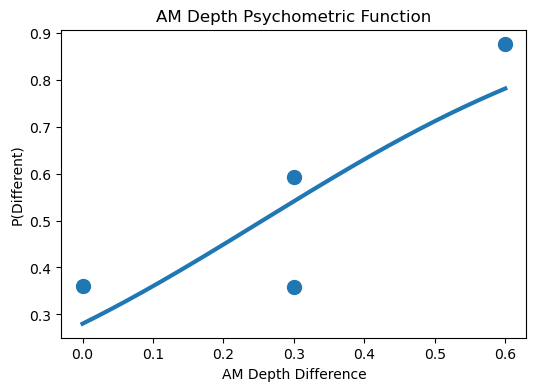

   Tone_Diff  Different
0        0.0   0.509259
1        1.0   0.506173
2        2.0   0.617284


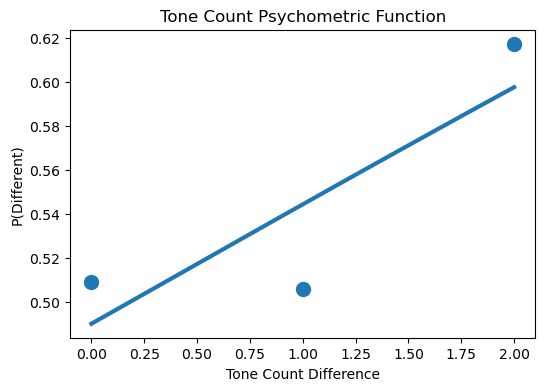

   AM_Diff  Different
0      0.0   0.361111
1      0.3   0.592593
2      0.3   0.358025
3      0.6   0.876543

   Tone_Diff  Different
0        0.0   0.509259
1        1.0   0.506173
2        2.0   0.617284


In [137]:
# Create binary response

pair_df["Different"] = (
    pair_df["Similarity"] < 0.5
).astype(int)

# Aggregate

am_summary = (
    pair_df
    .groupby("AM_Diff")["Different"]
    .mean()
    .reset_index()
)

print(am_summary)
from scipy.optimize import curve_fit
import numpy as np

def sigmoid(x,a,b):
    return 1/(1+np.exp(-(a*x+b)))

params,_ = curve_fit(
    sigmoid,
    am_summary["AM_Diff"],
    am_summary["Different"]
)
xfit = np.linspace(
    am_summary["AM_Diff"].min(),
    am_summary["AM_Diff"].max(),
    200
)

yfit = sigmoid(xfit,*params)

plt.figure(figsize=(6,4))

plt.scatter(
    am_summary["AM_Diff"],
    am_summary["Different"],
    s=100
)

plt.plot(
    xfit,
    yfit,
    linewidth=3
)

plt.xlabel("AM Depth Difference")
plt.ylabel("P(Different)")

plt.title(
    "AM Depth Psychometric Function"
)

plt.show()
tone_summary = (
    pair_df
    .groupby("Tone_Diff")["Different"]
    .mean()
    .reset_index()
)

print(tone_summary)
params,_ = curve_fit(
    sigmoid,
    tone_summary["Tone_Diff"],
    tone_summary["Different"]
)
xfit = np.linspace(
    tone_summary["Tone_Diff"].min(),
    tone_summary["Tone_Diff"].max(),
    200
)

yfit = sigmoid(xfit,*params)

plt.figure(figsize=(6,4))

plt.scatter(
    tone_summary["Tone_Diff"],
    tone_summary["Different"],
    s=100
)

plt.plot(
    xfit,
    yfit,
    linewidth=3
)

plt.xlabel("Tone Count Difference")
plt.ylabel("P(Different)")

plt.title(
    "Tone Count Psychometric Function"
)

plt.show()
print(am_summary)
print()
print(tone_summary)

In [138]:
pair_df["AM_Diff"] = pair_df["AM_Diff"].round(2)
am_summary = (
    pair_df
    .groupby("AM_Diff")["Different"]
    .mean()
    .reset_index()
)

print(am_summary)

   AM_Diff  Different
0      0.0   0.361111
1      0.3   0.475309
2      0.6   0.876543


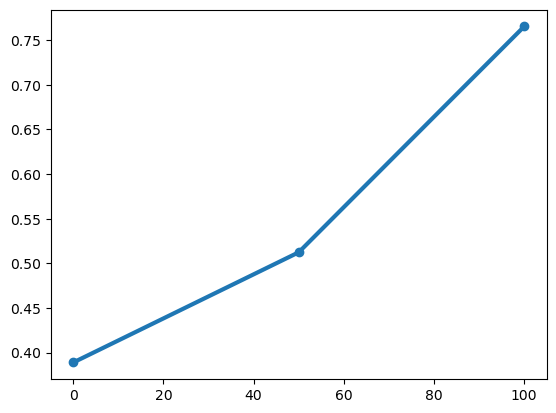

In [139]:
plt.plot(
    ifi_summary["IFI_Diff"],
    ifi_summary["Different"],
    marker='o',
    linewidth=3
)


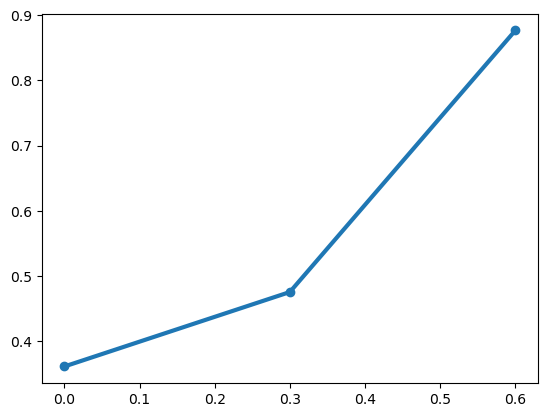

In [140]:
plt.plot(
    am_summary["AM_Diff"],
    am_summary["Different"],
    marker='o',
    linewidth=3
)

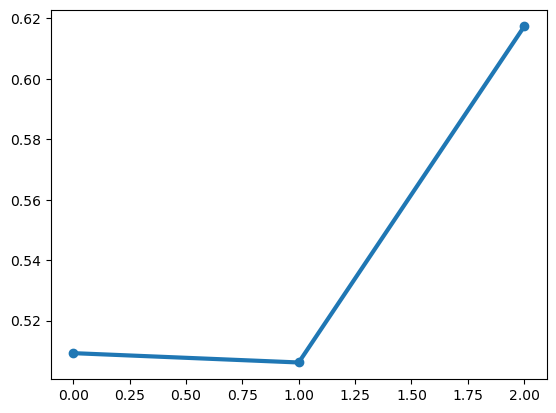

In [141]:
plt.plot(
    tone_summary["Tone_Diff"],
    tone_summary["Different"],
    marker='o',
    linewidth=3
)

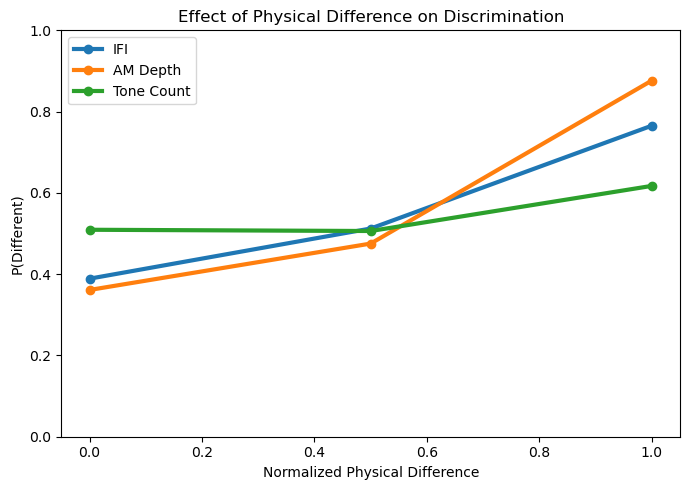

In [142]:
ifi_summary["Norm"] = ifi_summary["IFI_Diff"] / 100
am_summary["Norm"] = am_summary["AM_Diff"] / 0.6
tone_summary["Norm"] = tone_summary["Tone_Diff"] / 2

plt.figure(figsize=(7,5))

plt.plot(
    ifi_summary["Norm"],
    ifi_summary["Different"],
    marker='o',
    linewidth=3,
    label='IFI'
)

plt.plot(
    am_summary["Norm"],
    am_summary["Different"],
    marker='o',
    linewidth=3,
    label='AM Depth'
)

plt.plot(
    tone_summary["Norm"],
    tone_summary["Different"],
    marker='o',
    linewidth=3,
    label='Tone Count'
)

plt.xlabel(
    "Normalized Physical Difference"
)

plt.ylabel(
    "P(Different)"
)

plt.ylim(0,1)

plt.legend()

plt.title(
    "Effect of Physical Difference on Discrimination"
)

plt.tight_layout()
plt.show()

In [143]:
from sklearn.manifold import MDS

mds_3d = MDS(
    n_components=3,
    dissimilarity='precomputed',
    random_state=42
)

coords_3d = mds_3d.fit_transform(
    dissimilarity
)

print("3D Stress:", mds_3d.stress_)

3D Stress: 11.127088636791617


/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


In [144]:
mds3_df = stim_df.copy()

mds3_df["x"] = coords_3d[:,0]
mds3_df["y"] = coords_3d[:,1]
mds3_df["z"] = coords_3d[:,2]

mds3_df.head()

,ToneCount,IFI,AM,x,y,z
0,2,50,0.3,0.083640,-0.145827,-0.299650
1,2,50,0.6,-0.168044,0.167901,-0.272438
2,2,50,0.9,-0.266024,0.322960,-0.144559
3,2,100,0.3,-0.087057,-0.493020,0.031170
4,2,100,0.6,-0.177438,-0.046046,-0.060578


In [145]:
from scipy.stats import spearmanr

for dim in ["x","y","z"]:

    print(f"\n===== {dim} =====")

    for feature in [
        "ToneCount",
        "IFI",
        "AM"
    ]:

        r,p = spearmanr(
            mds3_df[dim],
            mds3_df[feature]
        )

        print(
            feature,
            round(r,3),
            round(p,4)
        )


===== x =====
ToneCount 0.582 0.0014
IFI -0.379 0.0515
AM -0.489 0.0096

===== y =====
ToneCount 0.157 0.4335
IFI -0.256 0.197
AM 0.903 0.0

===== z =====
ToneCount 0.215 0.2804
IFI 0.844 0.0
AM 0.093 0.6439


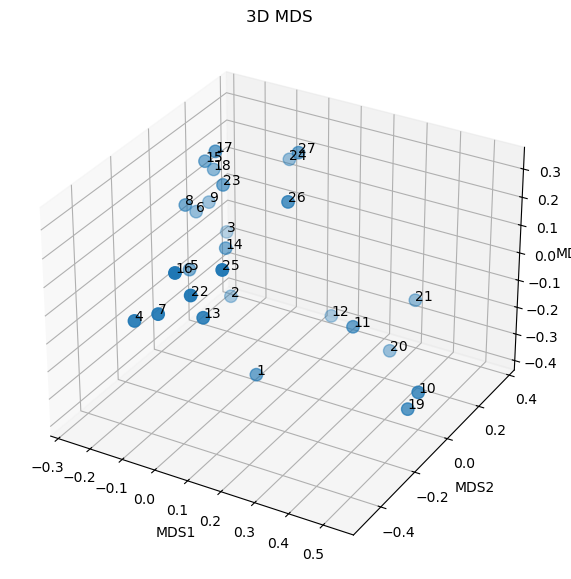

In [146]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(8,7))

ax = fig.add_subplot(
    111,
    projection='3d'
)

ax.scatter(
    mds3_df["x"],
    mds3_df["y"],
    mds3_df["z"],
    s=80
)

for i,row in mds3_df.iterrows():

    ax.text(
        row["x"],
        row["y"],
        row["z"],
        str(i+1)
    )

ax.set_xlabel("MDS1")
ax.set_ylabel("MDS2")
ax.set_zlabel("MDS3")

plt.title("3D MDS")

plt.show()

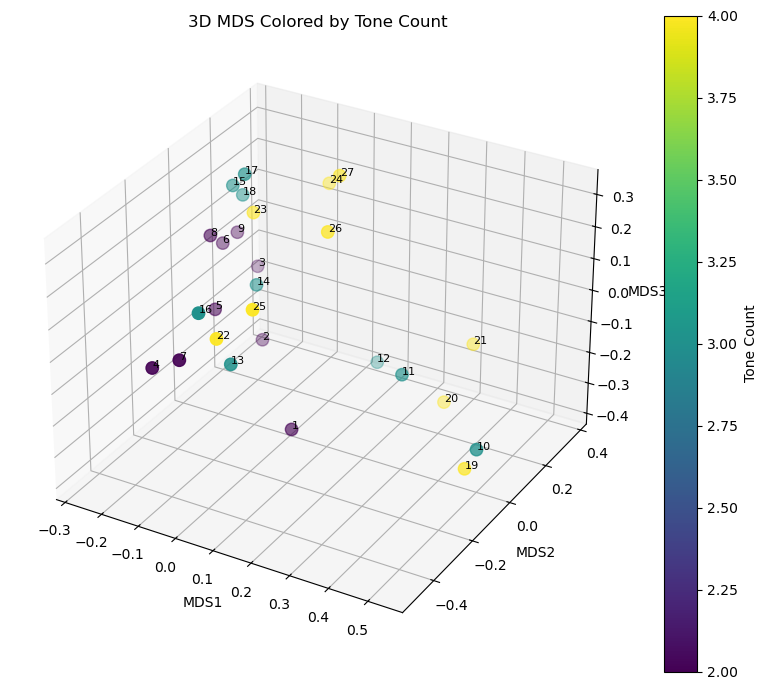

In [153]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8,7))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(
    coords_3d[:,0],
    coords_3d[:,1],
    coords_3d[:,2],
    c=stim_df["ToneCount"],
    cmap="viridis",
    s=80
)

# Add stimulus numbers
for i in range(len(coords_3d)):
    ax.text(
        coords_3d[i,0],
        coords_3d[i,1],
        coords_3d[i,2],
        str(i+1),
        fontsize=8
    )

ax.set_xlabel("MDS1")
ax.set_ylabel("MDS2")
ax.set_zlabel("MDS3")
ax.set_title("3D MDS Colored by Tone Count")

cbar = plt.colorbar(sc)
cbar.set_label("Tone Count")

plt.tight_layout()
plt.show()

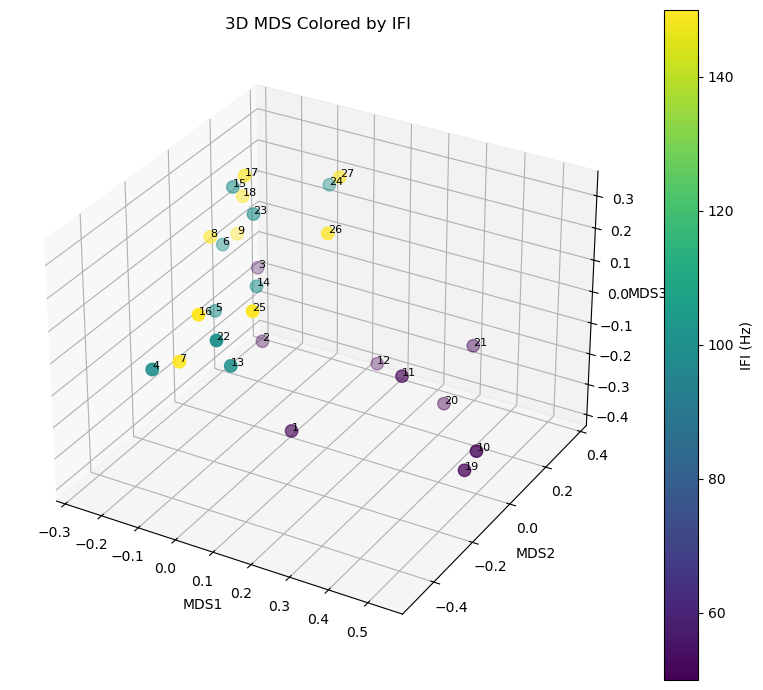

In [151]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8,7))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(
    coords_3d[:,0],
    coords_3d[:,1],
    coords_3d[:,2],
    c=stim_df["IFI"],
    cmap="viridis",
    s=80
)

for i in range(len(coords_3d)):
    ax.text(
        coords_3d[i,0],
        coords_3d[i,1],
        coords_3d[i,2],
        str(i+1),
        fontsize=8
    )

ax.set_xlabel("MDS1")
ax.set_ylabel("MDS2")
ax.set_zlabel("MDS3")
ax.set_title("3D MDS Colored by IFI")

cbar = plt.colorbar(sc)
cbar.set_label("IFI (Hz)")

plt.tight_layout()
plt.show()

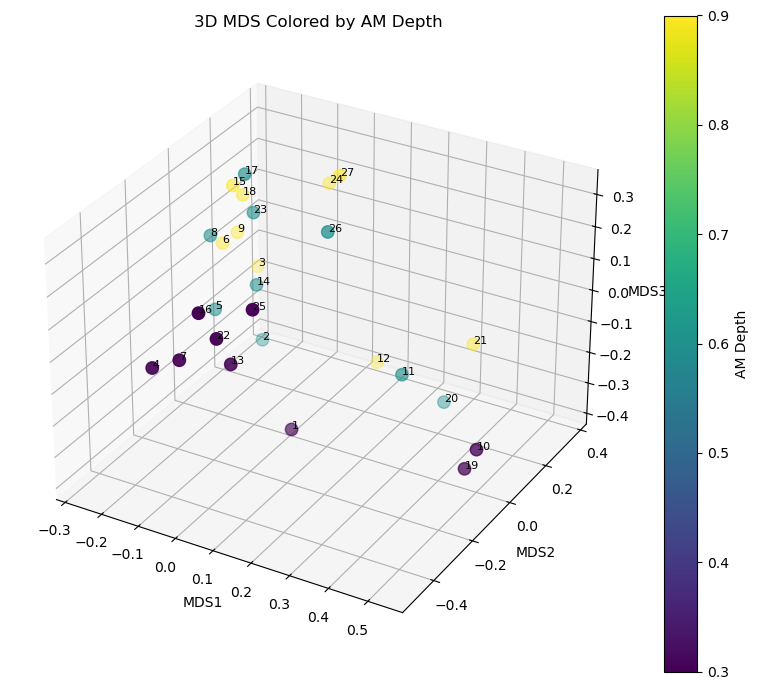

In [152]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8,7))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(
    coords_3d[:,0],
    coords_3d[:,1],
    coords_3d[:,2],
    c=stim_df["AM"],
    cmap="viridis",
    s=80
)

for i in range(len(coords_3d)):
    ax.text(
        coords_3d[i,0],
        coords_3d[i,1],
        coords_3d[i,2],
        str(i+1),
        fontsize=8
    )

ax.set_xlabel("MDS1")
ax.set_ylabel("MDS2")
ax.set_zlabel("MDS3")
ax.set_title("3D MDS Colored by AM Depth")

cbar = plt.colorbar(sc)
cbar.set_label("AM Depth")

plt.tight_layout()
plt.show()

In [62]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [63]:
import plotly.express as px

fig = px.scatter_3d(
    mds3_df,
    x="x",
    y="y",
    z="z",
    color="ToneCount",
    text=mds3_df.index+1
)

fig.show()

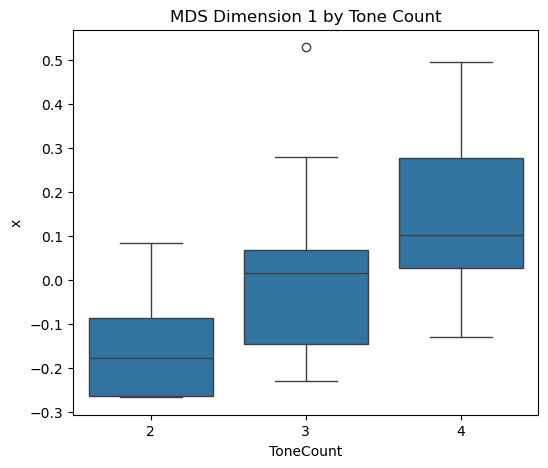

In [64]:
plt.figure(figsize=(6,5))

sns.boxplot(
    data=mds3_df,
    x="ToneCount",
    y="x"
)

plt.title(
    "MDS Dimension 1 by Tone Count"
)

plt.show()

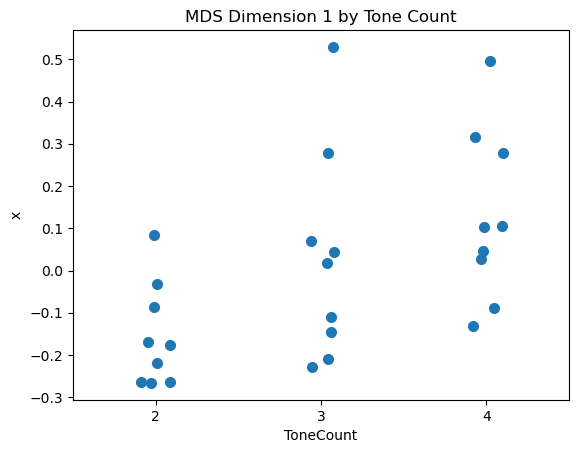

In [65]:
sns.stripplot(
    data=mds3_df,
    x="ToneCount",
    y="x",
    size=8
)

plt.title(
    "MDS Dimension 1 by Tone Count"
)

plt.show()

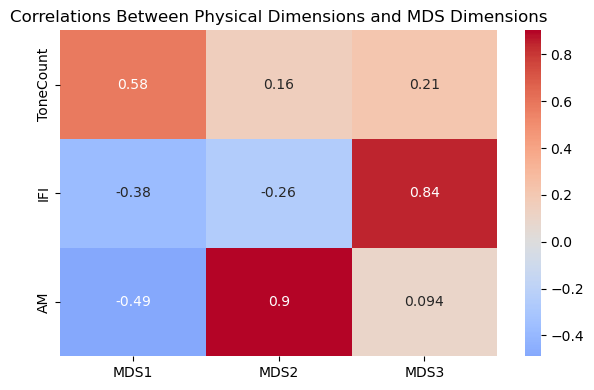

In [66]:
corrs = pd.DataFrame({

    "MDS1":[
        0.582,
        -0.379,
        -0.489
    ],

    "MDS2":[
        0.157,
        -0.256,
        0.903
    ],

    "MDS3":[
        0.215,
        0.844,
        0.094
    ]

},

index=[
    "ToneCount",
    "IFI",
    "AM"
])
plt.figure(figsize=(6,4))

sns.heatmap(
    corrs,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title(
    "Correlations Between Physical Dimensions and MDS Dimensions"
)

plt.tight_layout()
plt.show()

In [67]:
from sklearn.linear_model import LinearRegression

# Predict MDS1
X = stim_df[["ToneCount","IFI","AM"]]

for dim in ["x","y","z"]:

    y = mds3_df[dim]

    model = LinearRegression()
    model.fit(X,y)

    print("\n", dim)

    print("R² =", round(model.score(X,y),3))

    for name,coef in zip(
        ["ToneCount","IFI","AM"],
        model.coef_
    ):
        print(name, round(coef,3))


 x
R² = 0.685
ToneCount 0.141
IFI -0.003
AM -0.392

 y
R² = 0.87
ToneCount 0.039
IFI -0.002
AM 0.941

 z
R² = 0.783
ToneCount 0.046
IFI 0.005
AM 0.075


In [156]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import pandas as pd

X = stim_df[["ToneCount","IFI","AM"]]

ranges = X.max() - X.min()

dims = {
    "MDS1": coords_3d[:,0],
    "MDS2": coords_3d[:,1],
    "MDS3": coords_3d[:,2]
}

for name, y in dims.items():

    model = LinearRegression()
    model.fit(X, y)

    print("\n==========", name, "==========")
    print(f"R² = {r2_score(y, model.predict(X)):.3f}")

    effects = abs(model.coef_) * ranges

    result = pd.DataFrame({
        "Coefficient": model.coef_,
        "Range": ranges,
        "Effect Size": effects
    })

    print(result)


========== MDS1 ==========
R² = 0.685
           Coefficient  Range  Effect Size
ToneCount     0.141429    2.0     0.282858
IFI          -0.002504  100.0     0.250443
AM           -0.391562    0.6     0.234937

========== MDS2 ==========
R² = 0.870
           Coefficient  Range  Effect Size
ToneCount     0.038719    2.0     0.077437
IFI          -0.002036  100.0     0.203608
AM            0.940906    0.6     0.564543

========== MDS3 ==========
R² = 0.783
           Coefficient  Range  Effect Size
ToneCount     0.045991    2.0     0.091982
IFI           0.004532  100.0     0.453158
AM            0.075301    0.6     0.045181


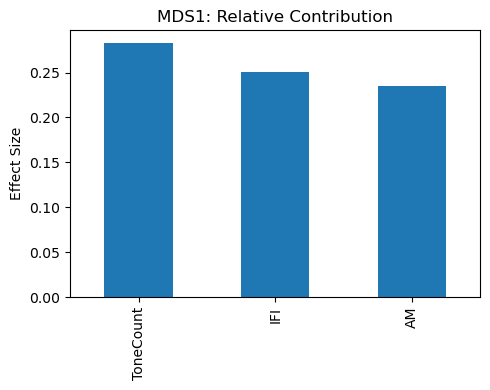

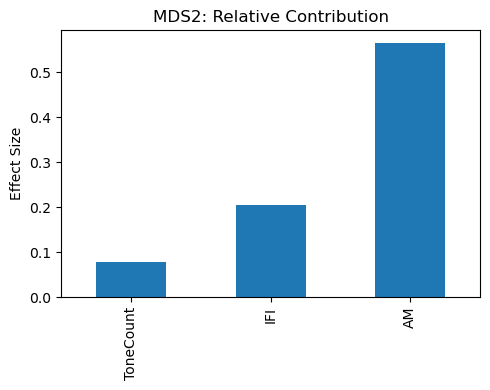

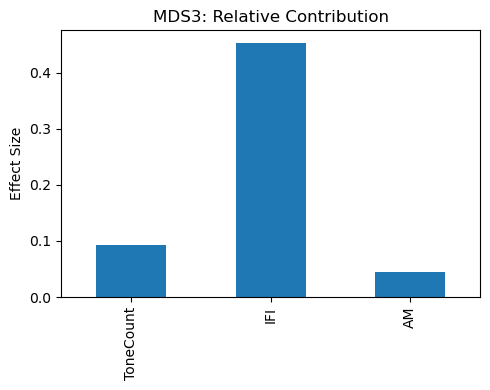

In [157]:
import matplotlib.pyplot as plt

for name, y in dims.items():

    model = LinearRegression()
    model.fit(X, y)

    effects = abs(model.coef_) * ranges

    plt.figure(figsize=(5,4))
    effects.plot(kind="bar")

    plt.ylabel("Effect Size")
    plt.title(f"{name}: Relative Contribution")
    plt.tight_layout()
    plt.show()

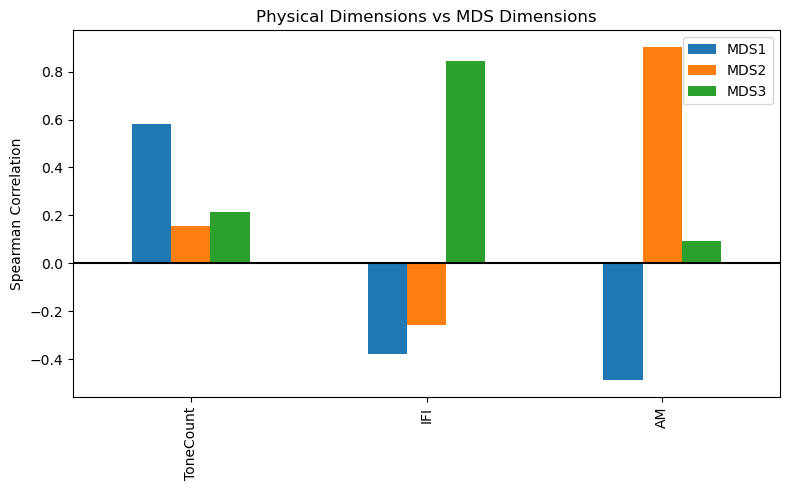

In [68]:
corrs.plot(
    kind="bar",
    figsize=(8,5)
)

plt.axhline(0,color='black')

plt.ylabel("Spearman Correlation")
plt.title(
    "Physical Dimensions vs MDS Dimensions"
)

plt.tight_layout()
plt.show()

In [69]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

X = stim_df[["ToneCount","IFI","AM"]]

scaler = StandardScaler()
Xz = scaler.fit_transform(X)

for dim in ["x","y","z"]:

    y = mds3_df[dim]

    model = LinearRegression()
    model.fit(Xz,y)

    print("\n", dim)

    print("R² =", round(model.score(Xz,y),3))

    for name,coef in zip(
        ["ToneCount","IFI","AM"],
        model.coef_
    ):
        print(name, round(coef,3))


 x
R² = 0.685
ToneCount 0.115
IFI -0.102
AM -0.096

 y
R² = 0.87
ToneCount 0.032
IFI -0.083
AM 0.23

 z
R² = 0.783
ToneCount 0.038
IFI 0.185
AM 0.018


In [154]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

X = stim_df[["ToneCount","IFI","AM"]]

X = StandardScaler().fit_transform(X)

model = LinearRegression()

model.fit(X, coords_3d[:,0])

print(model.coef_)

[ 0.11547648 -0.10224274 -0.09591268]


In [155]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import pandas as pd

# Raw predictor variables (no standardization)
X = stim_df[["ToneCount", "IFI", "AM"]]

# MDS coordinates
dims = {
    "MDS1": coords_3d[:,0],
    "MDS2": coords_3d[:,1],
    "MDS3": coords_3d[:,2]
}

for name, y in dims.items():

    model = LinearRegression()
    model.fit(X, y)

    y_pred = model.predict(X)

    print(f"\n{name}")
    print(f"R² = {r2_score(y, y_pred):.3f}")
    print(f"Intercept = {model.intercept_:.3f}")
    print(f"ToneCount = {model.coef_[0]:.6f}")
    print(f"IFI = {model.coef_[1]:.6f}")
    print(f"AM = {model.coef_[2]:.6f}")


MDS1
R² = 0.685
Intercept = 0.061
ToneCount = 0.141429
IFI = -0.002504
AM = -0.391562

MDS2
R² = 0.870
Intercept = -0.477
ToneCount = 0.038719
IFI = -0.002036
AM = 0.940906

MDS3
R² = 0.783
Intercept = -0.636
ToneCount = 0.045991
IFI = 0.004532
AM = 0.075301


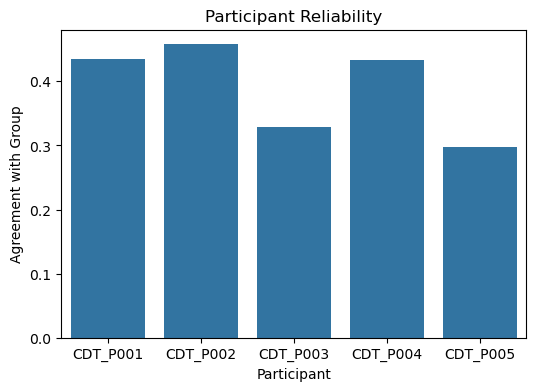

In [70]:
participant_scores = []

for pid in participant_ids:

    participant_matrix = matrices[pid]

    others = []

    for other_pid in participant_ids:

        if other_pid != pid:
            others.append(matrices[other_pid])

    group_without = np.nanmean(
        np.stack(others),
        axis=0
    )

    idx = np.triu_indices(27)

    p = participant_matrix[idx]
    g = group_without[idx]

    mask = ~np.isnan(p) & ~np.isnan(g)

    r,_ = pearsonr(
        p[mask],
        g[mask]
    )

    participant_scores.append(
        [pid,r]
    )

participant_scores = pd.DataFrame(
    participant_scores,
    columns=[
        "Participant",
        "Agreement"
    ]
)

participant_scores
plt.figure(figsize=(6,4))

sns.barplot(
    data=participant_scores,
    x="Participant",
    y="Agreement"
)

plt.ylabel(
    "Agreement with Group"
)

plt.title(
    "Participant Reliability"
)

plt.show()

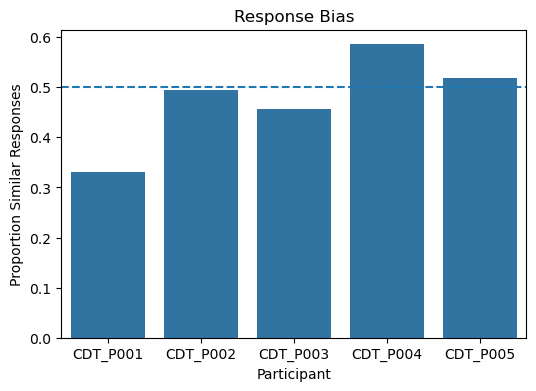

In [71]:
response_bias = []

for pid in participant_ids:

    mat = matrices[pid]

    idx = np.triu_indices(27,k=1)

    vals = mat[idx]

    vals = vals[~np.isnan(vals)]

    response_bias.append([

        pid,

        np.mean(vals)

    ])

response_bias = pd.DataFrame(
    response_bias,
    columns=[
        "Participant",
        "Proportion Similar"
    ]
)

response_bias
plt.figure(figsize=(6,4))

sns.barplot(
    data=response_bias,
    x="Participant",
    y="Proportion Similar"
)

plt.axhline(
    0.5,
    linestyle='--'
)

plt.ylabel(
    "Proportion Similar Responses"
)

plt.title(
    "Response Bias"
)

plt.show()

In [72]:
from scipy.stats import entropy

entropy_scores = []

for pid in participant_ids:

    mat = matrices[pid]

    idx = np.triu_indices(27,k=1)

    vals = mat[idx]

    vals = vals[~np.isnan(vals)]

    p_sim = np.mean(vals)
    p_dis = 1-p_sim

    H = entropy(
        [p_sim,p_dis],
        base=2
    )

    entropy_scores.append(
        [pid,H]
    )

entropy_df = pd.DataFrame(
    entropy_scores,
    columns=[
        "Participant",
        "Entropy"
    ]
)

entropy_df


,Participant,Entropy
0,CDT_P001,0.916379
1,CDT_P002,0.999900
2,CDT_P003,0.994456
3,CDT_P004,0.978718
4,CDT_P005,0.999069


In [75]:
%whos

Variable             Type                Data/Info
--------------------------------------------------
Axes3D               type                <class 'mpl_toolkits.mplot3d.axes3d.Axes3D'>
H                    float64             0.9990686614632538
LinearRegression     ABCMeta             <class 'sklearn.linear_mo<...>._base.LinearRegression'>
LogisticRegression   type                <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
MDS                  type                <class 'sklearn.manifold._mds.MDS'>
Path                 type                <class 'pathlib.Path'>
StandardScaler       type                <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                    DataFrame           Shape: (27, 3)
Xz                   ndarray             27x3: 81 elems, type `float64`, 648 bytes
agreement            list                n=10
agreement_matrix     ndarray             5x5: 25 elems, type `float64`, 200 bytes
am                   float               0.9
am_i    

In [76]:
import numpy as np

group_similarity = np.nanmean(
    np.stack(list(matrices.values())),
    axis=0
)

print(group_similarity.shape)

(27, 27)


In [77]:
pair_df = []

for i in range(27):
    for j in range(i+1,27):

        pair_df.append({

            "Stim1": i+1,
            "Stim2": j+1,

            "Similarity": group_similarity[i,j],

            "Tone1": stim_df.loc[i,"ToneCount"],
            "Tone2": stim_df.loc[j,"ToneCount"],

            "IFI1": stim_df.loc[i,"IFI"],
            "IFI2": stim_df.loc[j,"IFI"],

            "AM1": stim_df.loc[i,"AM"],
            "AM2": stim_df.loc[j,"AM"]

        })

pair_df = pd.DataFrame(pair_df)

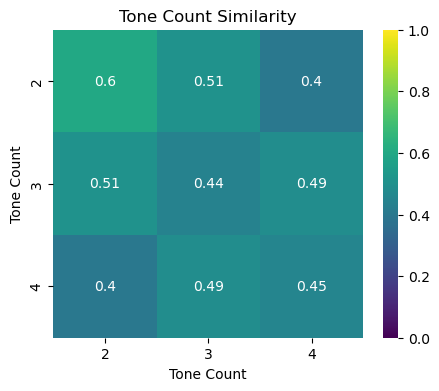

In [79]:
levels = [2,3,4]

tone_conf = np.zeros((3,3))

for i,t1 in enumerate(levels):
    for j,t2 in enumerate(levels):

        if t1==t2:

            vals = pair_df[
                (pair_df["Tone1"]==t1) &
                (pair_df["Tone2"]==t2)
            ]["Similarity"]

        else:

            vals1 = pair_df[
                (pair_df["Tone1"]==t1) &
                (pair_df["Tone2"]==t2)
            ]["Similarity"]

            vals2 = pair_df[
                (pair_df["Tone1"]==t2) &
                (pair_df["Tone2"]==t1)
            ]["Similarity"]

            vals = pd.concat([vals1,vals2])

        tone_conf[i,j] = vals.mean()
plt.figure(figsize=(5,4))

sns.heatmap(
    tone_conf,
    annot=True,
    cmap="viridis",
    vmin=0,
    vmax=1,
    xticklabels=levels,
    yticklabels=levels
)

plt.xlabel("Tone Count")
plt.ylabel("Tone Count")

plt.title("Tone Count Similarity")

plt.show()

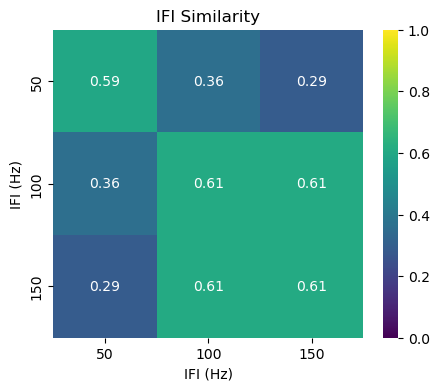

In [80]:
levels = [50,100,150]

ifi_conf = np.zeros((3,3))

for i,a in enumerate(levels):
    for j,b in enumerate(levels):

        if a==b:

            vals = pair_df[
                (pair_df["IFI1"]==a) &
                (pair_df["IFI2"]==b)
            ]["Similarity"]

        else:

            vals1 = pair_df[
                (pair_df["IFI1"]==a) &
                (pair_df["IFI2"]==b)
            ]["Similarity"]

            vals2 = pair_df[
                (pair_df["IFI1"]==b) &
                (pair_df["IFI2"]==a)
            ]["Similarity"]

            vals = pd.concat([vals1,vals2])

        ifi_conf[i,j] = vals.mean()

plt.figure(figsize=(5,4))

sns.heatmap(
    ifi_conf,
    annot=True,
    cmap="viridis",
    vmin=0,
    vmax=1,
    xticklabels=levels,
    yticklabels=levels
)

plt.xlabel("IFI (Hz)")
plt.ylabel("IFI (Hz)")

plt.title("IFI Similarity")

plt.show()

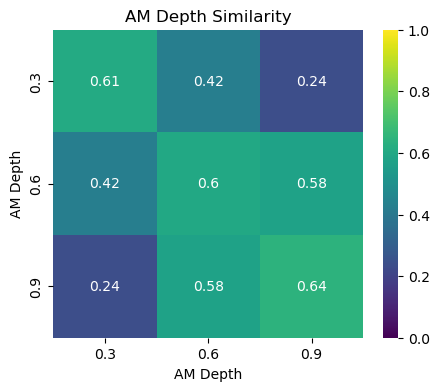

In [81]:
levels = [0.3,0.6,0.9]

am_conf = np.zeros((3,3))

for i,a in enumerate(levels):
    for j,b in enumerate(levels):

        if a==b:

            vals = pair_df[
                (pair_df["AM1"]==a) &
                (pair_df["AM2"]==b)
            ]["Similarity"]

        else:

            vals1 = pair_df[
                (pair_df["AM1"]==a) &
                (pair_df["AM2"]==b)
            ]["Similarity"]

            vals2 = pair_df[
                (pair_df["AM1"]==b) &
                (pair_df["AM2"]==a)
            ]["Similarity"]

            vals = pd.concat([vals1,vals2])

        am_conf[i,j] = vals.mean()
plt.figure(figsize=(5,4))

sns.heatmap(
    am_conf,
    annot=True,
    cmap="viridis",
    vmin=0,
    vmax=1,
    xticklabels=levels,
    yticklabels=levels
)

plt.xlabel("AM Depth")
plt.ylabel("AM Depth")

plt.title("AM Depth Similarity")

plt.show()

<Axes: >

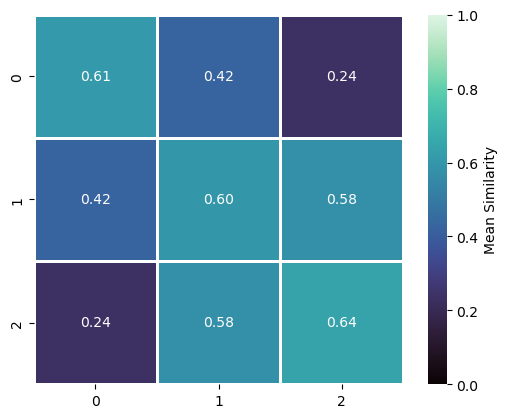

In [82]:
sns.heatmap(
    am_conf,
    annot=True,
    fmt=".2f",
    cmap="mako",      # or "viridis"
    square=True,
    linewidths=1,
    linecolor="white",
    vmin=0,
    vmax=1,
    cbar_kws={"label":"Mean Similarity"}
)